In [1]:
import os
import glob

os.environ['YOLO_VERBOSE'] = 'False'

import numpy as np
import pandas as pd
from ultralytics import YOLO
import matplotlib.pyplot as plt

pd.options.display.float_format = '{:.3f}'.format

%matplotlib inline

In [2]:
WEIGHTS_PTH = "results/filtered_v2/weights/best.pt"

BASE_PTH = "/home/klymy/data/people_detection/filtered_v2_10_sec"

VAL_PTH = os.path.join(BASE_PTH, "project.yaml")
HOLDOUT_PTH = os.path.join(BASE_PTH, "project_holdout.yaml")
ALGOTEST_PTH = os.path.join(BASE_PTH, "project_algotest.yaml")

VAL_IMGS_PTH = os.path.join(BASE_PTH, "images/val")
HOLDOUT_IMGS_PTH = os.path.join(BASE_PTH, "images/holdout")
ALGOTEST_IMGS_PTH = os.path.join(BASE_PTH, "images/algotest")

In [3]:
CONF_TH = 0.0
IOU_TH = 0.6

In [4]:
def print_metrics(metrics, conf_th=0, draw=True):
    data = [
        {
            "task": "box",
            "F1": metrics.box.f1[0],
            "P": metrics.box.p[0],
            "R": metrics.box.r[0],
            "MAP@50": metrics.box.map50,
        },
        {
            "task": "pose",
            "F1": metrics.pose.f1[0],
            "P": metrics.pose.p[0],
            "R": metrics.pose.r[0],
            "MAP@50": metrics.pose.map50,
        }
    ]
    print(pd.DataFrame(data))

    if not draw:
        return
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    x = np.linspace(conf_th, 1, num=len(metrics.box.f1_curve[0]), endpoint=True)
    plt.plot(x, metrics.box.f1_curve[0], label="F1")
    plt.plot(x, metrics.box.r_curve[0], label="R")
    plt.plot(x, metrics.box.p_curve[0], label="P")
    plt.grid(True)
    plt.ylim(-0.1, 1.1)
    plt.xlabel("Confidence")
    plt.legend()
    plt.title("BOX")

    plt.subplot(1, 2, 2)
    x = np.linspace(conf_th, 1, num=len(metrics.pose.f1_curve[0]), endpoint=True)
    plt.plot(x, metrics.pose.f1_curve[0], label="F1")
    plt.plot(x, metrics.pose.r_curve[0], label="R")
    plt.plot(x, metrics.pose.p_curve[0], label="P")
    plt.grid(True)
    plt.ylim(-0.1, 1.1)
    plt.xlabel("Confidence")
    plt.legend()
    plt.title("POSE");

## Default Validation

### Hold-out set

   task    F1     P     R  MAP@50
0   box 0.885 0.921 0.853   0.918
1  pose 0.903 0.939 0.869   0.946


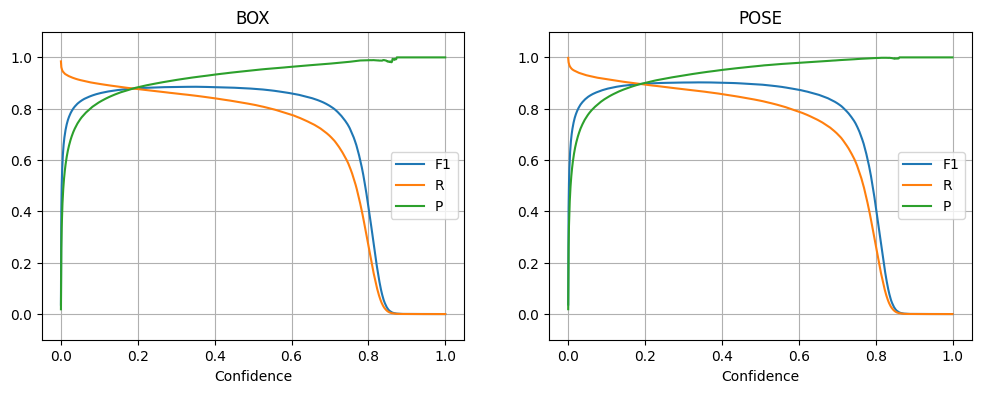

In [5]:
model = YOLO(WEIGHTS_PTH)
metrics = model.val(
    data=HOLDOUT_PTH,
    task="pose",
    device=[2],
    batch=256,
    verbose=False,
    conf=CONF_TH,
    iou=IOU_TH,
)

print_metrics(metrics, CONF_TH)

### Algotest set

   task    F1     P     R  MAP@50
0   box 0.865 0.912 0.823   0.884
1  pose 0.880 0.925 0.838   0.914


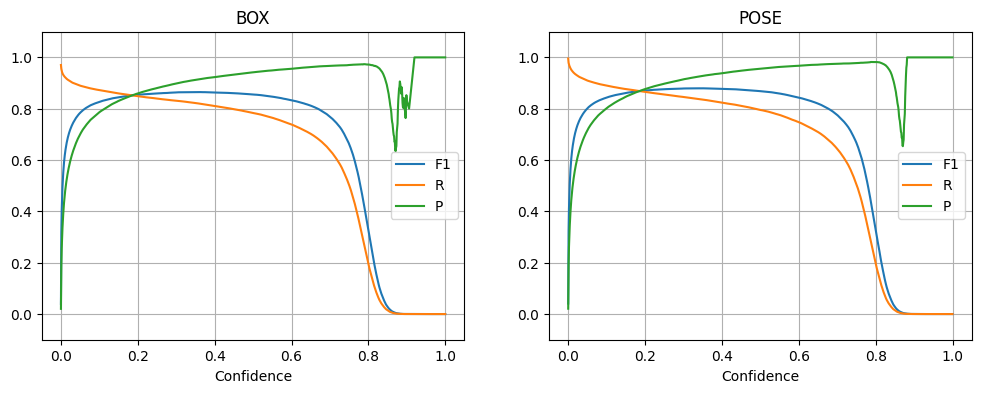

In [6]:
model = YOLO(WEIGHTS_PTH)
metrics = model.val(
    data=ALGOTEST_PTH,
    task="pose",
    device=[2],
    batch=256,
    verbose=False,
    conf=CONF_TH,
    iou=IOU_TH,
)

print_metrics(metrics, CONF_TH)

## CONF TH

In [7]:
model = YOLO(WEIGHTS_PTH)

for conf_th in np.arange(0.2, 0.51, 0.05):
    metrics = model.val(
        data=HOLDOUT_PTH,
        task="pose",
        device=[2],
        batch=128,
        verbose=False,
        conf=conf_th,
        iou=IOU_TH,
    )
    print(conf_th, ":")
    print_metrics(metrics, conf_th, draw=False)
    print(f"{'=' * 75}\n")

0.2 :
   task    F1     P     R  MAP@50
0   box 0.885 0.921 0.853   0.913
1  pose 0.903 0.939 0.869   0.933

0.25 :
   task    F1     P     R  MAP@50
0   box 0.885 0.921 0.853   0.910
1  pose 0.903 0.939 0.869   0.930

0.3 :
   task    F1     P     R  MAP@50
0   box 0.885 0.918 0.855   0.907
1  pose 0.902 0.937 0.870   0.926

0.35 :
   task    F1     P     R  MAP@50
0   box 0.886 0.923 0.851   0.904
1  pose 0.903 0.941 0.867   0.923

0.39999999999999997 :
   task    F1     P     R  MAP@50
0   box 0.884 0.933 0.841   0.900
1  pose 0.902 0.951 0.857   0.919

0.44999999999999996 :
   task    F1     P     R  MAP@50
0   box 0.882 0.942 0.829   0.896
1  pose 0.899 0.960 0.845   0.914

0.49999999999999994 :
   task    F1     P     R  MAP@50
0   box 0.878 0.950 0.816   0.890
1  pose 0.894 0.967 0.831   0.908



In [8]:
model = YOLO(WEIGHTS_PTH)

for conf_th in np.arange(0.2, 0.51, 0.05):
    metrics = model.val(
        data=ALGOTEST_PTH,
        task="pose",
        device=[2],
        batch=128,
        verbose=False,
        conf=conf_th,
        iou=IOU_TH,
    )
    print(conf_th, ":")
    print_metrics(metrics, conf_th, draw=False)
    print(f"{'=' * 75}\n")

0.2 :
   task    F1     P     R  MAP@50
0   box 0.865 0.912 0.823   0.884
1  pose 0.880 0.925 0.838   0.902

0.25 :
   task    F1     P     R  MAP@50
0   box 0.865 0.912 0.823   0.882
1  pose 0.880 0.925 0.838   0.899

0.3 :
   task    F1     P     R  MAP@50
0   box 0.865 0.911 0.824   0.880
1  pose 0.879 0.921 0.842   0.896

0.35 :
   task    F1     P     R  MAP@50
0   box 0.865 0.913 0.822   0.877
1  pose 0.879 0.928 0.836   0.892

0.39999999999999997 :
   task    F1     P     R  MAP@50
0   box 0.863 0.923 0.811   0.873
1  pose 0.877 0.938 0.824   0.888

0.44999999999999996 :
   task    F1     P     R  MAP@50
0   box 0.860 0.933 0.798   0.868
1  pose 0.874 0.948 0.811   0.883

0.49999999999999994 :
   task    F1     P     R  MAP@50
0   box 0.855 0.942 0.783   0.862
1  pose 0.868 0.956 0.795   0.876



In [9]:
TUNED_CONF_TH = 0.3

## IOU THRESHOLD

In [10]:
model = YOLO(WEIGHTS_PTH)

for iou_th in [0.45, 0.5, 0.65, 0.7]:
    metrics = model.val(
        data=HOLDOUT_PTH,
        task="pose",
        device=[2],
        batch=128,
        verbose=False,
        conf=TUNED_CONF_TH,
        iou=iou_th,
    )
    print(iou_th, ":")
    print_metrics(metrics, TUNED_CONF_TH, draw=False)
    print(f"{'=' * 75}\n")

0.45 :
   task    F1     P     R  MAP@50
0   box 0.888 0.922 0.856   0.907
1  pose 0.907 0.942 0.875   0.927

0.5 :
   task    F1     P     R  MAP@50
0   box 0.887 0.920 0.857   0.907
1  pose 0.906 0.938 0.875   0.927

0.65 :
   task    F1     P     R  MAP@50
0   box 0.884 0.920 0.850   0.907
1  pose 0.901 0.939 0.866   0.926

0.7 :
   task    F1     P     R  MAP@50
0   box 0.882 0.920 0.847   0.907
1  pose 0.899 0.938 0.863   0.925



In [11]:
model = YOLO(WEIGHTS_PTH)

for iou_th in [0.45, 0.5, 0.65, 0.7]:
    metrics = model.val(
        data=ALGOTEST_PTH,
        task="pose",
        device=[2],
        batch=128,
        verbose=False,
        conf=TUNED_CONF_TH,
        iou=iou_th,
    )
    print(iou_th, ":")
    print_metrics(metrics, TUNED_CONF_TH, draw=False)
    print(f"{'=' * 75}\n")

0.45 :
   task    F1     P     R  MAP@50
0   box 0.865 0.910 0.825   0.879
1  pose 0.882 0.925 0.844   0.896

0.5 :
   task    F1     P     R  MAP@50
0   box 0.866 0.909 0.826   0.879
1  pose 0.882 0.922 0.845   0.896



Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x71b40aa5a5f0>
Traceback (most recent call last):
  File "/home/klymy/.pyenv/versions/3.10.13/envs/pgpytrain/lib/python3.10/site-packages/torch/utils/data/dataloader.py", line 1479, in __del__
    self._shutdown_workers()
  File "/home/klymy/.pyenv/versions/3.10.13/envs/pgpytrain/lib/python3.10/site-packages/torch/utils/data/dataloader.py", line 1462, in _shutdown_workers
    if w.is_alive():
  File "/home/klymy/.pyenv/versions/3.10.13/lib/python3.10/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x71b40aa5a5f0>
Traceback (most recent call last):
  File "/home/klymy/.pyenv/versions/3.10.13/envs/pgpytrain/lib/python3.10/site-packages/torch/utils/data/dataloader.py", line 1479, in __del__
    self._shutdown_workers()


0.65 :
   task    F1     P     R  MAP@50
0   box 0.864 0.911 0.821   0.879
1  pose 0.878 0.922 0.837   0.895

0.7 :
   task    F1     P     R  MAP@50
0   box 0.861 0.911 0.816   0.879
1  pose 0.875 0.924 0.831   0.895



In [12]:
TUNED_IOU_TH = 0.5

## Visuzlization

In [13]:
model = YOLO(WEIGHTS_PTH)

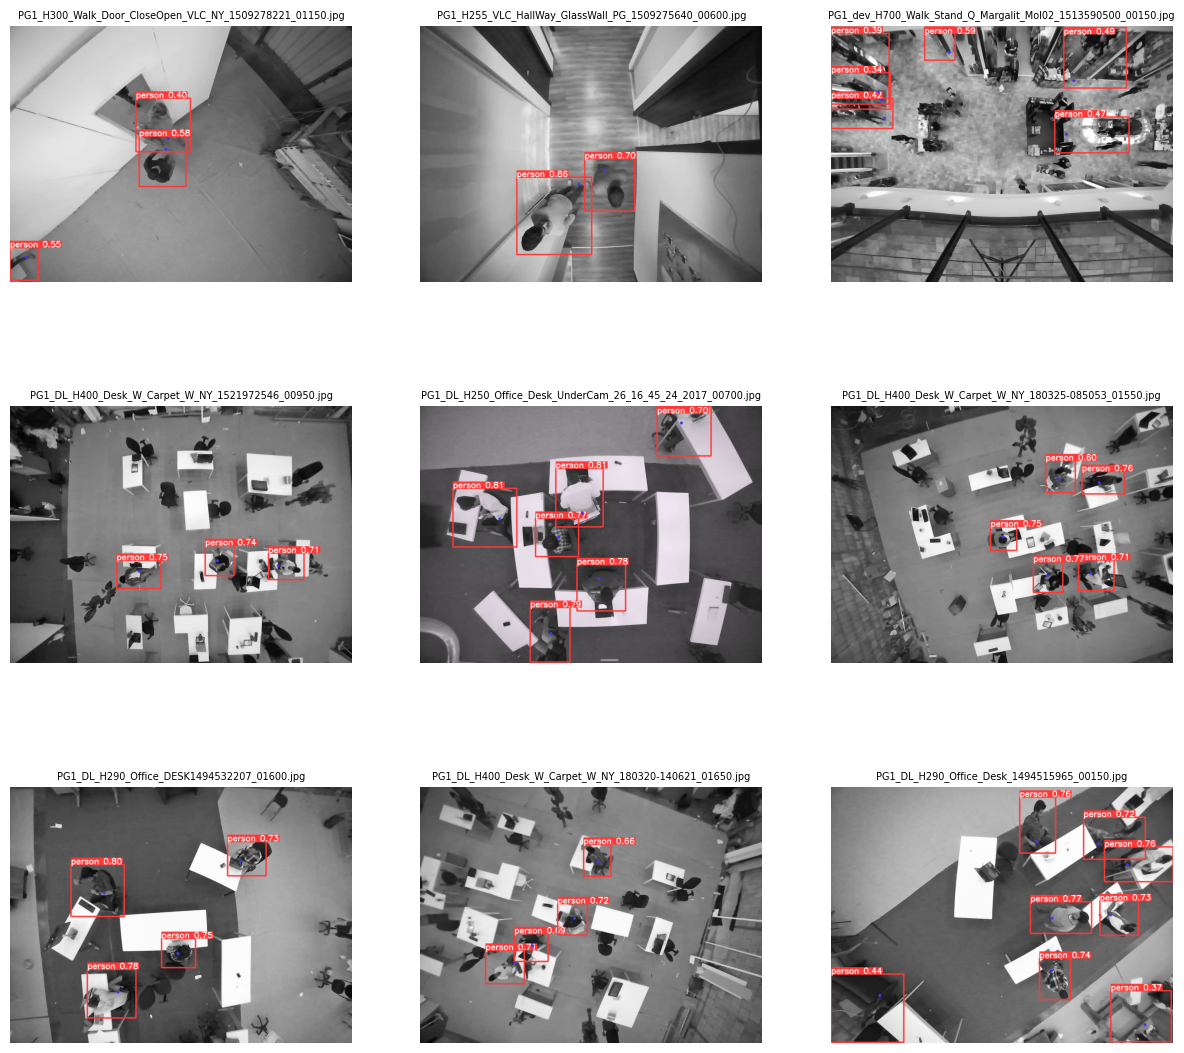

In [14]:
img_pths = glob.glob(os.path.join(VAL_IMGS_PTH, "*.jpg"))

np.random.seed(42)
np.random.shuffle(img_pths)
img_pths = img_pths[:9]

results = model(img_pths, conf=TUNED_CONF_TH, iou=TUNED_IOU_TH)

plt.figure(figsize=(15, 14))
for i, result in enumerate(results):
    plt.subplot(3, 3, i + 1)
    plt.imshow(result.plot()[:, :, ::-1])
    plt.axis('off')
    # plt.tight_layout()
    plt.title(result.path.split("/")[-1], fontsize=7)

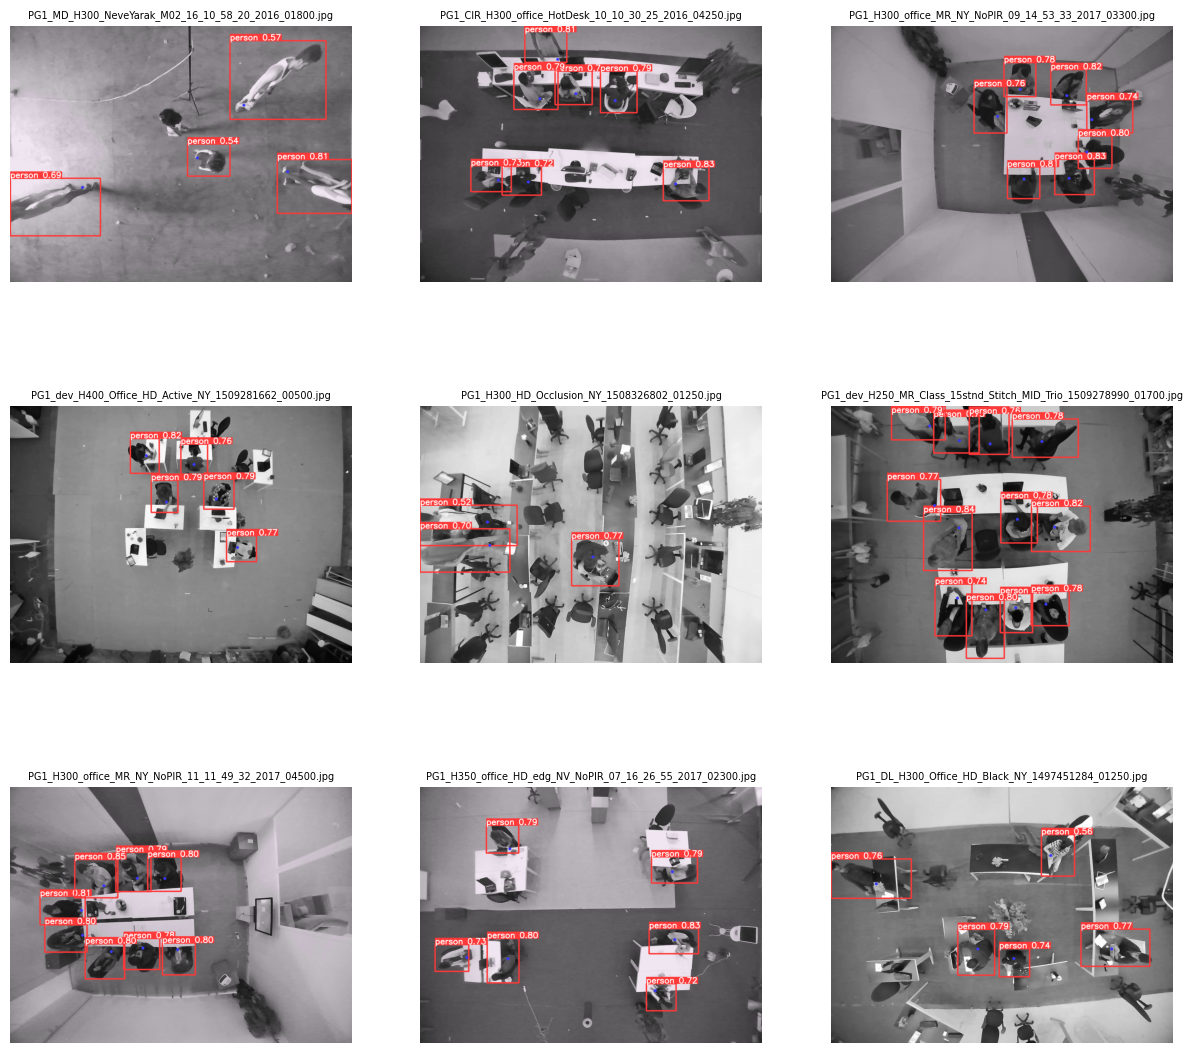

In [15]:
img_pths = glob.glob(os.path.join(HOLDOUT_IMGS_PTH, "*.jpg"))

np.random.seed(42)
np.random.shuffle(img_pths)
img_pths = img_pths[:9]

results = model(img_pths, conf=TUNED_CONF_TH, iou=TUNED_IOU_TH)

plt.figure(figsize=(15, 14))
for i, result in enumerate(results):
    plt.subplot(3, 3, i + 1)
    plt.imshow(result.plot()[:, :, ::-1])
    plt.axis('off')
    # plt.tight_layout()
    plt.title(result.path.split("/")[-1], fontsize=7)